
Logistic Regression
              precision    recall  f1-score   support

           0       0.67      0.70      0.69       500
           1       0.69      0.66      0.67       500

    accuracy                           0.68      1000
   macro avg       0.68      0.68      0.68      1000
weighted avg       0.68      0.68      0.68      1000



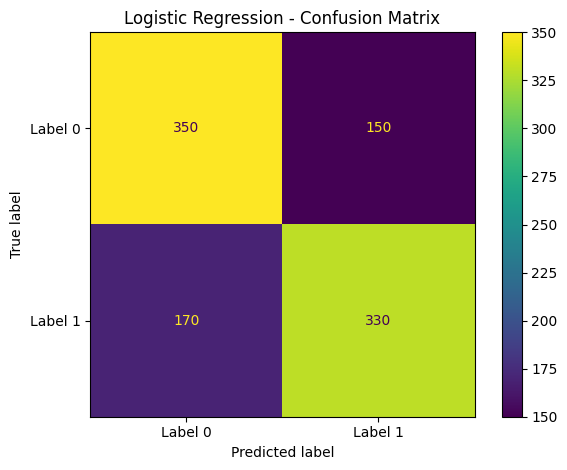


Random Forest
              precision    recall  f1-score   support

           0       0.65      0.67      0.66       500
           1       0.66      0.64      0.65       500

    accuracy                           0.65      1000
   macro avg       0.65      0.65      0.65      1000
weighted avg       0.65      0.65      0.65      1000



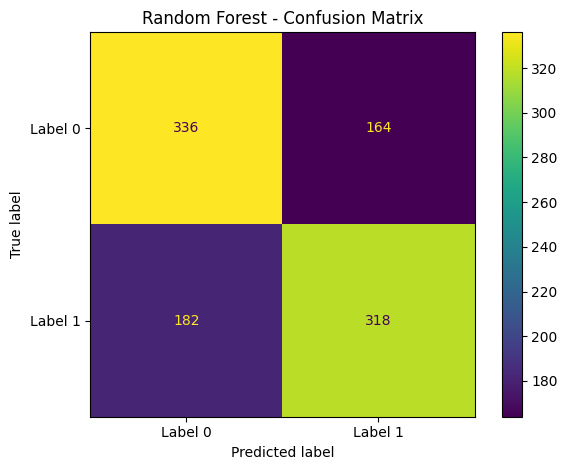


XGBoost
              precision    recall  f1-score   support

           0       0.67      0.67      0.67       500
           1       0.67      0.67      0.67       500

    accuracy                           0.67      1000
   macro avg       0.67      0.67      0.67      1000
weighted avg       0.67      0.67      0.67      1000



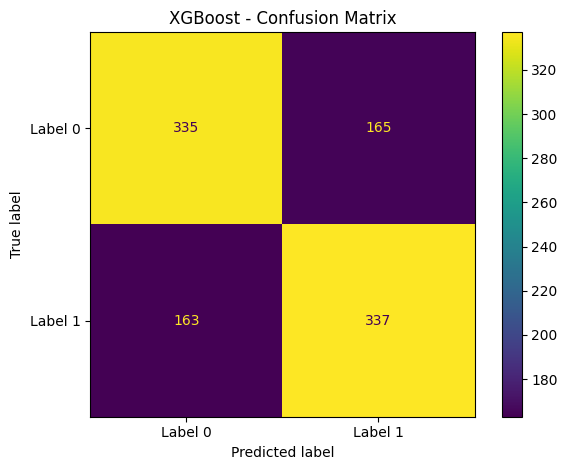


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.680,0.6875,0.660,0.6735,0.7375
1,XGBoost,0.672,0.6713,0.674,0.6727,0.7209
2,Random Forest,0.654,0.6598,0.636,0.6477,0.7099


<Figure size 1000x500 with 0 Axes>

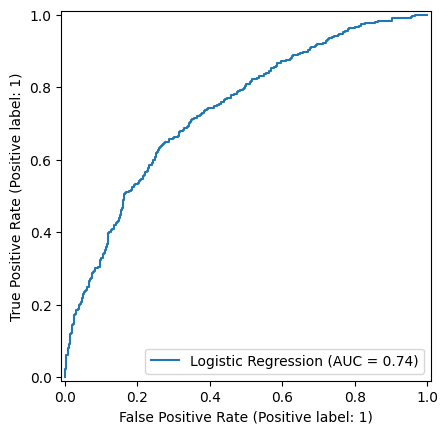

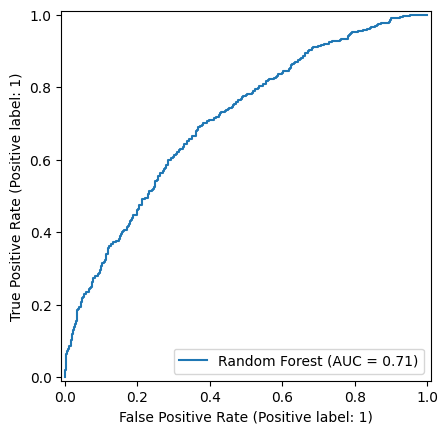

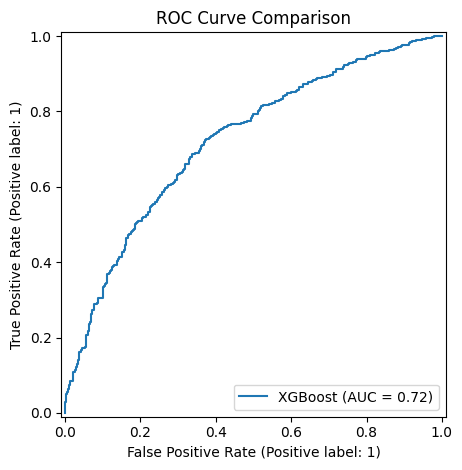

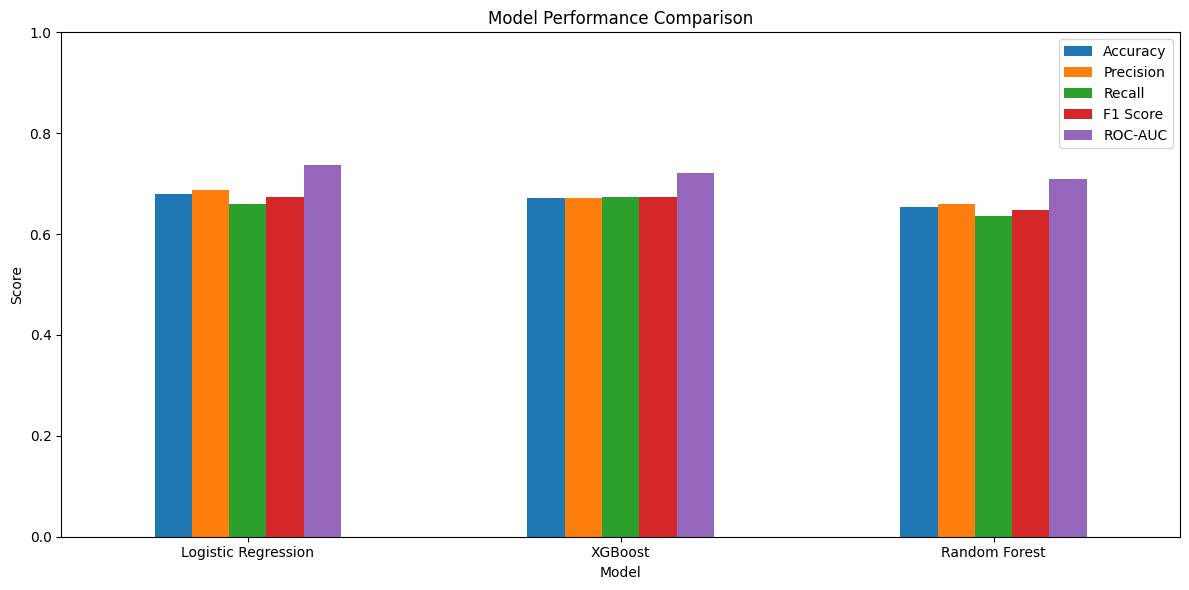


Selected model: Logistic Regression
Model comparison saved to: c:\Users\saura\OneDrive\Desktop\early_disease_prediction\data\model_comparison.csv
Evaluation summary saved to: c:\Users\saura\OneDrive\Desktop\early_disease_prediction\data\reports\evaluation_summary.json
Final model saved to: c:\Users\saura\OneDrive\Desktop\early_disease_prediction\models\best_model.joblib

MODEL EVALUATION COMPLETED


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

project_path = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = project_path / "data"
model_path = project_path / "models"
report_path = data_path / "reports"

report_path.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(data_path / "dataset.csv")

if "patient_id" in df.columns:
    df = df.drop(columns=["patient_id"])

X = df.drop(columns=["label"])
y = df["label"].astype(int)

feature_columns = joblib.load(model_path / "feature_columns.joblib")
X = X[feature_columns]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Random Forest": "random_forest.joblib",
    "XGBoost": "xgboost.joblib"
}

evaluation_results = []
trained_models = {}

for model_name, filename in model_files.items():
    filepath = model_path / filename

    if not filepath.exists():
        print(f"Skipping {model_name}: model file not found.")
        continue

    model = joblib.load(filepath)
    trained_models[model_name] = model

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

    evaluation_results.append(metrics)

    print(f"\n{model_name}")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))

    ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(y_test, predictions),
        display_labels=["Label 0", "Label 1"]
    ).plot()

    plt.title(f"{model_name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

results_df = pd.DataFrame(evaluation_results)

if results_df.empty:
    raise FileNotFoundError(
        "No trained models were found. Run 04_model_training.ipynb first."
    )

results_df = results_df.sort_values(
    "F1 Score", ascending=False
).reset_index(drop=True)

print("\nMODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

results_df.to_csv(
    data_path / "model_comparison.csv",
    index=False
)

plt.figure(figsize=(10, 5))

for model_name, model in trained_models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=model_name
    )

plt.title("ROC Curve Comparison")
plt.tight_layout()
plt.show()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

results_df.set_index("Model")[metric_columns].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

joblib.dump(best_model, model_path / "best_model.joblib")

summary = {
    "selected_model": best_model_name,
    "selection_metric": "F1 Score",
    "metrics": results_df.iloc[0].to_dict(),
    "dataset_type": "Synthetic demonstration data",
    "clinical_warning": (
        "These metrics do not establish clinical validity "
        "or real-world disease prediction performance."
    )
}

import json

with open(
    report_path / "evaluation_summary.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(summary, file, indent=4, default=str)

print("\nSelected model:", best_model_name)
print("Model comparison saved to:", data_path / "model_comparison.csv")
print("Evaluation summary saved to:", report_path / "evaluation_summary.json")
print("Final model saved to:", model_path / "best_model.joblib")
print("\nMODEL EVALUATION COMPLETED")